# 05 — Renovação

**Pergunta de negócio.** Na renovação de cada grupo, quanto reajustar a taxa, e quanto confiar na experiência
do próprio grupo em vez da taxa manual?

**1. Pooling.** Nível de pooling do grupo $g$, com $\bar C_g$ o capital médio das vidas ativas e $R$ a retenção:

$$P_g = \min\!\left(R,\ \max(\text{piso},\ 3\,\bar C_g)\right).$$

Sinistros acima de $P_g$ saem da experiência do grupo; o excesso esperado, $\sum_v q_v m_v \max(C_v - P_g, 0)$,
vira encargo de pooling.

**2. Experiência contra a taxa manual**, em valor limitado ao pooling ($m_v$: fator da taxa manual):

$$
A/E_g = \frac{\sum \min(\text{sinistro}, P_g) + \text{IBNR}_g}{\sum_v q_v\, t_v\, m_v \min(C_v, P_g)}.
$$

**3. IBNR.** Padrão de aviso da carteira por chain ladder mensal; por grupo, estilo Bornhuetter-Ferguson:
$\text{IBNR}_g = \sum_{\text{meses}} E^{a\,priori}_{g,m}\,\big(1 - p(\text{idade}_m)\big)$, com $p$ a proporção avisada.

**4. Credibilidade** $Z_g$, por dois métodos:
- **mercado** (flutuação limitada, regra da raiz em vidas-ano $n_g$): $Z_g = \min\!\left(1, \sqrt{n_g / n_{plena}}\right)$, zero abaixo do mínimo;
- **Bühlmann-Straub**, com peso $w_g = n_{ef,g}$: $Z_g = \dfrac{w_g}{w_g + k}$, $\ k = \dfrac{s^2}{a}$ (variância dentro ÷ variância entre grupos, estimadas nos dados).

**5. Reajuste.** Com $\text{Custo}_g$ o custo limitado na manual sobre o censo atual (idades atualizadas):

$$
\text{prêmio puro}_g = \text{Custo}_g \times \big[Z_g\, A/E_g + (1 - Z_g)\big] + \text{encargo de pooling}_g,
\qquad
\text{taxa comercial} = \frac{\text{taxa pura}}{1 - \text{carregamento}}.
$$

O reajuste é taxa comercial ÷ taxa vigente − 1, com piso e teto, comparado com a regra contratual por faixa de
sinistralidade. Parâmetros em `config/renovacao.yaml` (carregamento, piso, teto e retenção são ilustrativos).

In [1]:
import sys, warnings
warnings.filterwarnings("ignore", message="Efeitos aleatórios com variância nula")   # informado explicitamente no notebook 04
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from vgpricing.graficos import estilo
estilo()
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from vgpricing.config import carregar_config
from vgpricing.tabua import obter_tabua
from vgpricing import manual as M, renovacao as R, backtest as B
from vgpricing.glmm import r_disponivel

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
cfg, cm, cr = (carregar_config(n, RAIZ) for n in ("base", "manual", "renovacao"))
# anos de choque: a mesma política da taxa manual vale para a experiência da renovação (uma fonte só)
cr = {**cr, "excluir_anos_experiencia": cm["excluir_anos_experiencia"]}
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message=".*coluna lx.*")
    tabua = obter_tabua(cfg, RAIZ)
assert not tabua.placeholder, "Tábua oficial não carregada"
limpo = RAIZ / cfg["pasta_processados"] / "limpo"
dados = {t: pd.read_parquet(limpo / f"{t}.parquet") for t in ("estipulantes", "vidas", "sinistros", "premios")}
tabela = M.carregar_tabela(RAIZ / "artefatos/fatores_manual.yaml")      # gerada no notebook 04
REF = pd.Timestamp(cfg["data_referencia"])
ren = R.renovar_carteira(dados, tabua, tabela, cr, REF)
xp, P = ren["experiencia"], ren["pooling"]
pd.Series({"A/E a priori contra a manual (contagem)": ren["ae_apriori"][0],
           "A/E a priori contra a manual (valor limitado)": ren["ae_apriori"][1],
           "nível de pooling mediano (R$)": P.median(),
           "parcela do custo esperado acima do pooling": xp["V_excesso"].sum() / (xp["V_manual"].sum() + xp["V_excesso"].sum()),
           "parcela dos sinistros que saiu da experiência": 1 - xp["V"].sum() / xp["V_total"].sum()}).to_frame("carteira")
# validação (SES e backtest) e artefato de credibilidade para a cotação
from joblib import Memory
from vgpricing import publicos as P, avaliacao as A
cp = carregar_config("publicos", RAIZ)
cache = Memory(RAIZ / "data/processed/cache", verbose=0).cache
prioris = M.carregar_tabela(RAIZ / "artefatos/prioris_soa.yaml")
METODO = tabela["meta"]["modelo_escolhido"]
M.salvar_tabela({"meta": {"metodo": "Bühlmann-Straub (actuar), A/E em valor limitado contra a taxa manual",
                          "data_avaliacao": str(cfg["data_referencia"]), "peso": "número efetivo de óbitos (n_ef)"},
                 "k_bs": float(ren["bs"]["k"])}, RAIZ / "artefatos/credibilidade.yaml")

## 1. IBNR

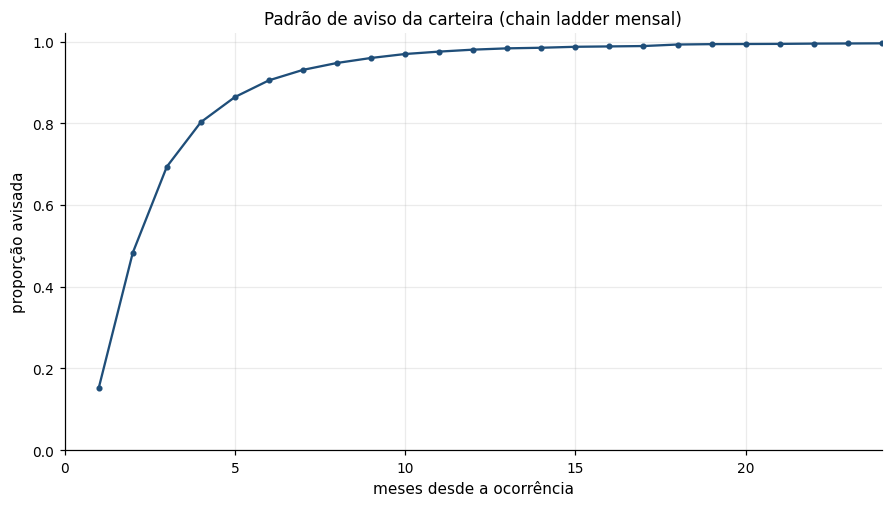

,N,IBNR_n,V,IBNR_v
início do ano-apólice,,,,
2017,148.0000,0.0000,"11,556,781.8330",0.0000
2018,310.0000,0.0000,"25,238,474.4403",0.0000
2019,434.0000,0.0000,"33,053,550.8294",0.0000
2020,564.0000,0.0000,"44,665,066.0691",0.0000
2021,619.0000,0.0000,"50,339,619.4284",0.0000
2022,539.0000,0.2875,"42,913,231.5931","22,679.8382"
2023,560.0000,2.5148,"51,188,863.6719","257,843.2038"
2024,591.0000,23.2504,"49,811,439.5038","2,191,525.9804"
2025,247.0000,108.5335,"22,908,458.4158","9,262,736.1204"


In [2]:
pn = ren["padrao_contagem"]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(pn["idade_meses"], pn["proporcao_avisada"], marker="o", ms=3, color="#1f4e79")
ax.set_xlim(0, 24); ax.set_ylim(0, 1.02); ax.set_xlabel("meses desde a ocorrência"); ax.set_ylabel("proporção avisada")
ax.set_title("Padrão de aviso da carteira (chain ladder mensal)"); plt.show()
ib = xp.groupby(xp["inicio_ano"].dt.year)[["N", "IBNR_n", "V", "IBNR_v"]].sum().rename_axis("início do ano-apólice")
ib.loc["total"] = ib.sum()
ib

A regra contratual usa IBNR fixo de 15% do prêmio, independentemente da idade da experiência. Aqui o IBNR
depende de quanto tempo passou desde cada mês de exposição.

## 2. Credibilidade

In [3]:
bs = ren["bs"]
pd.Series({"s² (variância dentro)": bs["s2"], "a (variância entre grupos)": bs["a"], "k = s²/a": bs["k"],
           "A/E médio da carteira": bs["media_carteira"]}).to_frame("Bühlmann-Straub")

,Bühlmann-Straub
s² (variância dentro),2.3129
a (variância entre grupos),0.1847
k = s²/a,12.5249
A/E médio da carteira,1.0384


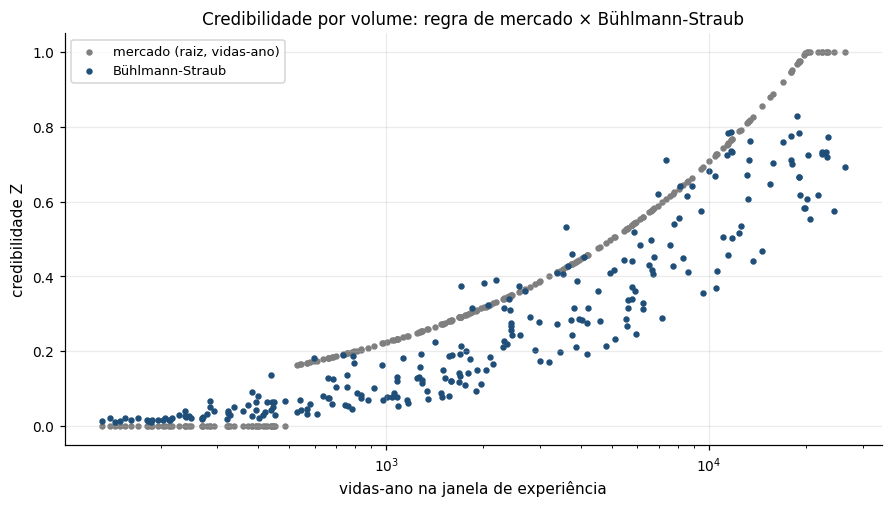

In [4]:
f = ren["fatores"]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(f["vidas_ano"], f["Z_mercado"], s=10, label="mercado (raiz, vidas-ano)", color="#7f7f7f")
ax.scatter(f["vidas_ano"], f["Z_bs"], s=10, label="Bühlmann-Straub", color="#1f4e79")
ax.set_xscale("log"); ax.set_xlabel("vidas-ano na janela de experiência"); ax.set_ylabel("credibilidade Z"); ax.legend()
ax.set_title("Credibilidade por volume: regra de mercado × Bühlmann-Straub")
fig.savefig(RAIZ / "docs/figuras/renovacao_credibilidade.png", dpi=110)
plt.show()

- Para o mesmo número de vidas-ano, o Bühlmann-Straub dá credibilidades diferentes conforme a concentração de
  capital (o peso é $n_{ef}$); a regra de mercado só olha vidas-ano.
- Com os limiares de mercado (plena em 20 mil vidas-ano), a regra da raiz dá **mais** credibilidade que a
  estimada nos dados. No levantamento da SOA com seguradoras de grupo, uma delas relatou o mesmo ao testar a
  própria fórmula com dados históricos.

## 3. Reajuste técnico × regra contratual

In [5]:
rj = ren["reajustes"]
display(pd.DataFrame({"reajuste técnico (aplicado)": rj["reajuste_aplicado"].describe(),
                      "regra contratual": rj["reajuste_regra"].describe()}))
pd.crosstab(pd.cut(rj["reajuste_aplicado"], [-1, -0.05, 0.05, 0.2, 1], labels=["redução", "estável", "até 20%", "acima de 20%"]),
            rj["reajuste_regra"], margins=True)

,reajuste técnico (aplicado),regra contratual
count,250.0000,250.0000
mean,-0.0873,0.0326
std,0.1072,0.0602
min,-0.1500,0.0000
25%,-0.1500,0.0000
50%,-0.1500,0.0000
75%,-0.0601,0.0000
max,0.4000,0.1500


reajuste_regra,0.0000,0.1000,0.1500,All
reajuste_aplicado,,,,
redução,141,8,40,189
estável,23,1,5,29
até 20%,22,2,2,26
acima de 20%,6,0,0,6
All,192,11,47,250


A regra contratual só aumenta, olha só o último ano, usa IBNR fixo e não distingue um grupo de 50 vidas de
um de 5 mil. Quando aplicada por anos seguidos, acumula aumentos mesmo quando a sinistralidade alta foi sorte;
por isso a taxa técnica sai abaixo da vigente em muitos grupos desta carteira, e o piso limita a redução. O
reajuste técnico recalcula a taxa manual sobre as idades atuais e dá a cada grupo a credibilidade que o volume
dele justifica. A decisão comercial continua sendo da área; o reajuste técnico é o ponto de partida.

## 4. Validação com dados reais: credibilidade nas seguradoras do SES

Cada seguradora faz o papel de um grupo: a sinistralidade anual do ramo 0993 (sinistro ocorrido ÷ prêmio ganho) é a
experiência, e o prêmio ganho é o peso. Para cada ano-alvo, usando só os 5 anos anteriores, prevê-se a
sinistralidade de cada seguradora por três métodos:

$$
\hat{x}_i^{\text{mercado}} = \bar{x}, \qquad \hat{x}_i^{\text{própria}} = \bar{x}_i, \qquad
\hat{x}_i^{\text{BS}} = Z_i\,\bar{x}_i + (1 - Z_i)\,\bar{x}, \quad Z_i = \frac{w_i}{w_i + k},
$$

com $k$ de Bühlmann-Straub (`actuar::cm`) estimado nessa mesma janela. Pontuação: erro quadrático ponderado pelo
prêmio, só nos anos-alvo normais (2019, 2023, 2024, 2025); IC da diferença por bootstrap pareado.

In [6]:
ses = P.ler_ses(cp, RAIZ)
anual = P.sinistralidade_anual(ses[ses["ano"] <= 2025], "0993", por_cia=True)
anual = anual[anual["premio_ganho"] > 1e7].rename(columns={"coenti": "unidade", "sinistralidade": "x"})
anual["w"] = anual["premio_ganho"] / 1e6                       # em R$ milhões
ALVOS, PANDEMIA = list(range(2019, 2026)), (2020, 2021, 2022)
res = {pol: B.credibilidade_mercado(anual, ALVOS, 5, anos_excluidos_historico=exc, anos_alvo_excluidos=PANDEMIA, n_boot=2000)
       for pol, exc in [("manter 2020-2022 no histórico", ()), ("excluir 2020-2022 do histórico", PANDEMIA)]}
ses_res = pd.concat({p: r["resumo"].set_index("metodo") for p, r in res.items()}, names=["política", "método"])
ses_res.to_csv(RAIZ / "resultados/renovacao_ses.csv")
ses_res

erro quadrático ponderado  \
política                       método                                           
manter 2020-2022 no histórico  Bühlmann-Straub                         0.0134   
                               experiência própria                     0.0139   
                               média da carteira                       0.0494   
excluir 2020-2022 do histórico Bühlmann-Straub                         0.0108   
                               experiência própria                     0.0107   
                               média da carteira                       0.0445   

                                                    dif. vs experiência própria  \
política                       método                                             
manter 2020-2022 no histórico  Bühlmann-Straub                          -0.0005   
                               experiência própria                       0.0000   
                               média da carteira                         0.0355   
excluir 2020-2022 do histórico Bühlmann-Straub                           0.0002   
                               experiência própria                       0.0000   
                               média da carteira                         0.0338   

                                                    IC95 inf  IC95 sup  
política                       método                                   
manter 2020-2022 no histórico  Bühlmann-Straub       -0.0018    0.0007  
                               experiência própria    0.0000    0.0000  
                               média da carteira      0.0216    0.0501  
excluir 2020-2022 do histórico Bühlmann-Straub       -0.0013    0.0012  
                               experiência própria    0.0000    0.0000  
                               média da carteira      0.0225    0.0466

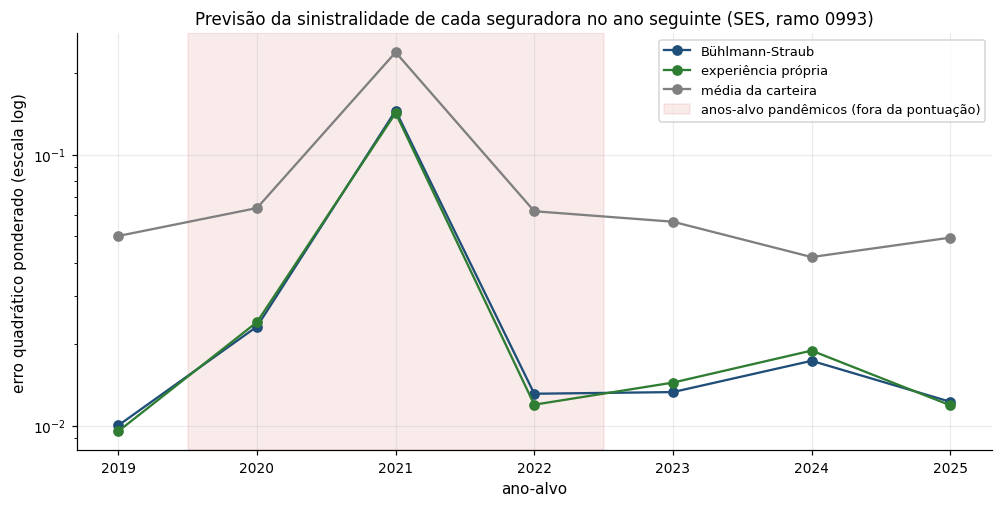

,Z mediano,k
ano_alvo,,
2019,0.8328,85.1007
2020,0.8625,67.0550
2021,0.8914,78.6048
2022,0.7335,221.5464
2023,0.7590,188.2987
2024,0.7947,144.5908
2025,0.7702,160.7977


In [7]:
d = res["manter 2020-2022 no histórico"]["detalhe"]
e = d.groupby(["ano_alvo", "metodo"]).apply(lambda g: np.average(g["erro2"], weights=g["w"]), include_groups=False).unstack()
fig, ax = plt.subplots(figsize=(9, 4.5))
for m, cor in zip(e.columns, ["#1f4e79", "#2e7d32", "#7f7f7f"]):
    ax.plot(e.index, e[m], "o-", color=cor, label=m)
ax.axvspan(2019.5, 2022.5, color="#c00000", alpha=0.08, label="anos-alvo pandêmicos (fora da pontuação)")
ax.set_yscale("log"); ax.set_xlabel("ano-alvo"); ax.set_ylabel("erro quadrático ponderado (escala log)")
ax.set_title("Previsão da sinistralidade de cada seguradora no ano seguinte (SES, ramo 0993)"); ax.legend()
fig.savefig(RAIZ / "docs/figuras/renovacao_ses.png", dpi=110)
plt.show()
z = d[d["metodo"] == "Bühlmann-Straub"].groupby("ano_alvo")[["Z", "k"]].agg({"Z": "median", "k": "first"})
z.rename(columns={"Z": "Z mediano"})

**Leitura:**
- A experiência própria erra **menos da metade** que a média do mercado: as seguradoras diferem de forma estrutural
  (carregamento, mix de coberturas e de produtos), e a experiência própria captura isso.
- Bühlmann-Straub fica praticamente igual à experiência própria, porque as seguradoras são grandes e o Z mediano é
  alto. É o resultado que a teoria prevê: com volume, a credibilidade vai para perto de 1.
- Os anos-alvo pandêmicos têm erro de outra ordem de grandeza para todos os métodos, e **tirar 2020–2022 do
  histórico** reduz o erro nos anos normais seguintes: a mesma política adotada para a taxa manual da carteira.
- Para unidades pequenas, como a maioria dos estipulantes de vida em grupo, Z é baixo e a credibilidade faz diferença
  (teste `test_credibilidade_mercado_favorece_credibilidade_com_unidades_pequenas` e parte 4).

## 5. Qual credibilidade usar? Backtest com vários anos-alvo

Para cada ano-alvo $Y$, a taxa manual é estimada com o mesmo método do 04, só com a experiência até $Y$ menos a
maturação e **só com os sinistros avisados até a data da renovação** (com o IBNR residual completado pelo chain
ladder daquela data), e o $k$ de Bühlmann-Straub vem da carteira no início de $Y$. Ficam fora os anos-apólice que começam em
2020 ou 2021, porque atravessam o ano pandêmico.

In [8]:
EXC = tuple(cm["excluir_anos_experiencia"])
ANOS = [2019, 2022, 2023, 2024]
# cada taxa manual por ano-alvo fica no cache (o método entra na chave): reexecutar não reestima o que não mudou
bt = B.executar_varios_anos(dados, tabua, lambda data: cache(B.tabela_ate)(dados, tabua, data, METODO, cm, prioris, EXC),
                            cr, cfg["data_referencia"], ANOS)
print("Anos-alvo por ano de início:", bt["por_grupo"]["ano_alvo"].value_counts().sort_index().to_dict(),
      "| k de Bühlmann-Straub por ano:", {a: round(k, 1) for a, k in bt["k_por_ano"].items()})
bt["comparacao_deviance"].to_csv(RAIZ / "resultados/renovacao_backtest.csv", index=False)
bt["comparacao_deviance"]

Anos-alvo por ano de início: {2019: 173, 2022: 250, 2023: 250, 2024: 17} | k de Bühlmann-Straub por ano: {2019: 2.8, 2022: inf, 2023: 9.1, 2024: 12.0}


,modelo,deviance,diferença vs Só taxa manual (Z = 0),IC95 inf,IC95 sup,significativa
0,Só taxa manual (Z = 0),964.9704,0.0000,0.0000,0.0000,False
1,"Credibilidade de mercado (raiz, vidas-ano)",899.4108,-65.5596,-115.5520,-22.7044,True
2,Bühlmann-Straub (n efetivo),915.1612,-49.8092,-95.5653,-8.7988,True
3,Só experiência (Z = 1),"1,670.9943",706.0239,398.4951,"1,069.0433",True


In [9]:
bt["resumo"]

,método,deviance (contagem),erro relativo (valor limitado),previsto/observado (valor limitado),S/P carteira,dispersão da S/P entre grupos
0,Só taxa manual (Z = 0),964.9704,0.0464,0.9529,0.6889,0.8699
1,"Credibilidade de mercado (raiz, vidas-ano)",899.4108,0.0417,0.9401,0.6980,0.8549
2,Bühlmann-Straub (n efetivo),915.1612,0.0437,0.9599,0.6840,0.8553
3,Só experiência (Z = 1),"1,670.9943",0.0447,0.9438,0.6953,21.7437
4,Regra contratual 75/85% (prêmio efetivamente c...,NaN,NaN,NaN,0.5373,0.6702


**Gráfico de sinistralidade** (CAS 7.2.3): os grupos ordenados pelo custo técnico previsto na renovação dividido
pelo prêmio que de fato pagaram no ano-alvo (regra contratual). Se a sinistralidade observada sobe ao longo das
faixas, o preço praticado não acompanha o risco que o reajuste técnico enxerga: é o argumento de negócio para ele.

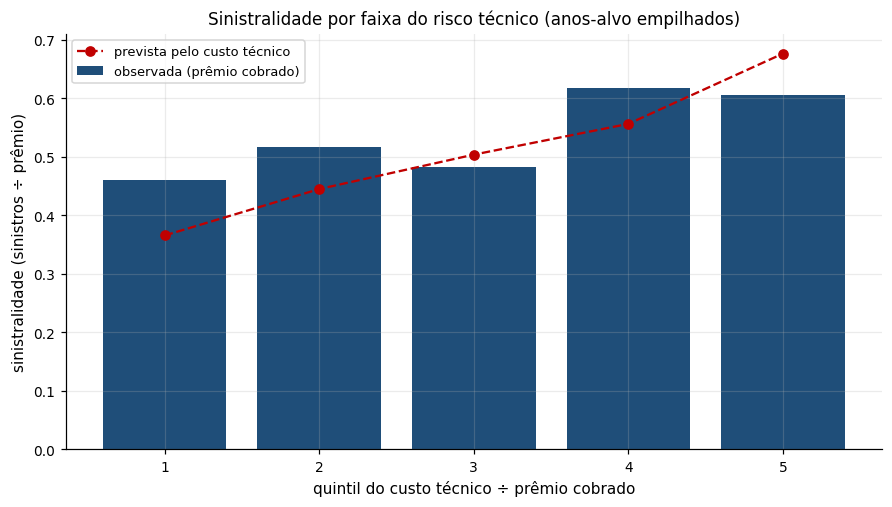

,premio,sinistro,previsto,sinistralidade observada,sinistralidade prevista
faixa,,,,,
1,"45,708,969.8720","21,035,700.0000","16,707,104.6297",0.4602,0.3655
2,"47,631,827.5199","24,642,200.0000","21,190,409.1038",0.5173,0.4449
3,"47,356,253.5813","22,881,400.0000","23,855,049.0295",0.4832,0.5037
4,"46,094,611.6954","28,507,800.0000","25,644,094.6482",0.6185,0.5563
5,"48,041,154.3555","29,100,300.0000","32,500,771.2936",0.6057,0.6765


In [10]:
g = bt["por_grupo"].dropna(subset=["premio_emitido"]).copy()
g["custo_tecnico"] = g["V_manual"] * g["fator_bs"] + g["V_excesso"]
sp = A.sinistralidade_por_faixa(g, "custo_tecnico", "premio_emitido", "V_total", n=5)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(sp.index, sp["sinistralidade observada"], color="#1f4e79", label="observada (prêmio cobrado)")
ax.plot(sp.index, sp["sinistralidade prevista"], "o--", color="#c00000", label="prevista pelo custo técnico")
ax.set_xlabel("quintil do custo técnico ÷ prêmio cobrado"); ax.set_ylabel("sinistralidade (sinistros ÷ prêmio)")
ax.set_title("Sinistralidade por faixa do risco técnico (anos-alvo empilhados)"); ax.legend()
fig.savefig(RAIZ / "docs/figuras/renovacao_sinistralidade.png", dpi=110)
plt.show()
sp

## Conclusões
- **Credibilidade com dados reais (SES):** a experiência própria e Bühlmann-Straub superam com folga a média do
  mercado; tirar os anos pandêmicos do histórico reduz o erro nos anos normais seguintes.
- **Renovação com vários anos-alvo:** as credibilidades preveem significativamente melhor que só a taxa manual, e só
  a experiência é significativamente pior. A escolha entre a regra de mercado e Bühlmann-Straub fica para o
  champion/challenger na base real (a diferença entre elas não foi testada diretamente).
- **Artefato:** o k de Bühlmann-Straub vai para `artefatos/credibilidade.yaml`, usado na cotação de grupos com
  histórico (06).

**Limitações:** o SES mede sinistralidade com carregamento e todas as coberturas, por seguradora (não por
estipulante); na carteira, os efeitos e o choque são hipóteses do gerador.